# 05 — Activity Supply: How Much Is Visible Online? (Exploratory, Baix Empordà)

## 1. Objective and research questions

**Objective.** This is a first, brief exploration of the **supply side**. It asks how much of the activity offer for seniors in one comarca can be seen online, using official open data and the municipalities' own websites. It is **not** an inventory of activities. It measures *online visibility*, which is a different thing from *existence*: lack of online information does not mean lack of activities (CLAUDE.md §10).

**Why Baix Empordà.** It is the proposed fieldwork comarca for profile P2 (seasonal, medium/large; decision D-018). It continues the Costa Brava case, and it has 36 municipalities of very different sizes (40,463 residents aged 60+).

**Research questions**

1. **Open cultural agenda.** How many events does the Generalitat's open cultural agenda list for the comarca? Where, of what kind, and how many target seniors?
2. **Facility registers.** Do the official registers list senior leisure facilities (casals de gent gran), or only care services?
3. **Municipal websites.** Do town hall websites show an activities agenda and a page for seniors?
4. **Visibility by municipality.** How does online visibility vary with municipality size? Where is the offer "invisible" online?
5. **Implications.** What does this mean for designing the supply inventory?

## 2. Data sources

| ID | Dataset | Content used | Retrieved | Notes |
|---|---|---|---|---|
| DS-17 | [Agenda cultural de Catalunya (per localitzacions)](https://analisi.transparenciacatalunya.cat/d/rhpv-yr4f), Generalitat open data | All events located in Baix Empordà (title, dates, categories, free/paid, description, municipality) | 2026-11-26 | Events entered by organisers into the Generalitat's agenda; the archive starts in 2018 |
| DS-18 | [Equipaments de Catalunya](https://analisi.transparenciacatalunya.cat/d/8gmd-gz7i) | All registered facilities in Baix Empordà; Catalonia-wide count of the category "Casals de gent gran" | 2026-11-26 | Register of public facilities |
| DS-19 | [Registre d'entitats, serveis i establiments socials](https://analisi.transparenciacatalunya.cat/d/ivft-vegh) | Social services registered in Baix Empordà | 2026-11-26 | Care services (residences, day centres…), not leisure |
| DS-20 | [Dades d'ens locals – Ajuntaments](https://analisi.transparenciacatalunya.cat/d/vevv-8fvw) | Municipal code, population and **official website** of the 36 municipalities | 2026-11-26 | Personal data in the dataset (mayors, etc.) were not downloaded |
| DS-21 | Municipal websites (own observation) | One request to each homepage, plus one to the agenda page if linked: links to an agenda and to senior / casal pages, and senior terms on the agenda page | 2026-11-26 | `scripts/check_municipal_websites.py`; only observations are stored, not page copies |
| — | Notebook 04 output | Residents and residents 60+ by municipality, 2025 (Idescat census) | — | `data/processed/municipality_seniors_2025.csv` |

Downloads: `python scripts/download_open_data.py` (manifest in `data/raw/opendata_gencat/MANIFEST.csv`) and `python scripts/check_municipal_websites.py data/raw/opendata_gencat/ajuntaments_baix_emporda.json`. Generalitat open data are published under its open-data terms of use (attribution).

In [1]:
import json
import re
import sys
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from tfg.paths import DATA_RAW, DATA_PROCESSED, REPORTS_FIGURES

OPEN = DATA_RAW / "opendata_gencat"
WEB = DATA_RAW / "web_checks"
REPORTS_FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
REFERENCE_DATE = pd.Timestamp("2026-11-26")   # retrieval date of all sources
LAST_12M_START = REFERENCE_DATE - pd.DateOffset(years=1)

## 3. Data preparation

### 3.1 Municipalities (DS-20 + notebook 04)

In [2]:
municipalities = pd.DataFrame(json.loads((OPEN / "ajuntaments_baix_emporda.json").read_text(encoding="utf-8")))
municipalities["mun_code"] = municipalities["codi_municipi"].str[:6]          # 10-digit register code -> 6-digit
seniors = pd.read_csv(DATA_PROCESSED / "municipality_seniors_2025.csv", dtype={"mun_code": str})
seniors = seniors.loc[seniors["comarca_name"] == "Baix Empordà"]
mun = seniors.merge(municipalities[["mun_code", "web"]], on="mun_code", how="outer", validate="one_to_one", indicator=True)
assert mun["_merge"].eq("both").all() and len(mun) == 36
mun = mun.drop(columns="_merge").set_index("mun_code")
mun["size_class"] = pd.cut(mun["pop_total"], [0, 1_000, 5_000, np.inf], right=False,
                           labels=["< 1,000 residents", "1,000–4,999", "≥ 5,000"])
print(mun["size_class"].value_counts().sort_index().to_dict())
print("Residents 60+ in the comarca:", int(mun["pop_60_plus"].sum()))

{'< 1,000 residents': 20, '1,000–4,999': 8, '≥ 5,000': 8}
Residents 60+ in the comarca: 40463


### 3.2 Open cultural agenda (DS-17)

The agenda identifies each event's place by a text slug (`…/baix-emporda/palamos`). Slugs are matched to official municipality names after normalising accents and articles. Three municipalities appear in the agenda under shorter or older names, and these are mapped explicitly.

In [3]:
events_raw = pd.DataFrame(json.loads((OPEN / "agenda_cultural_baix_emporda.json").read_text(encoding="utf-8")))
# The dataset has one row per event *location/occurrence*: exact duplicate rows are dropped, and an
# "event" is counted as a distinct event code (`codi`) — per municipality for municipal counts.
events = events_raw.drop_duplicates().copy()
print(f"Rows: {len(events_raw)} | after dropping exact duplicates: {len(events)} | distinct event codes: {events['codi'].nunique()}")
events["place_slug"] = events["comarca_i_municipi"].str.replace("agenda:ubicacions/girona/baix-emporda", "", regex=False).str.strip("/")

def slugify(text):
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]+", "-", text).strip("-")

def idescat_name_to_slug(name):
    # "Bisbal d'Empordà, la" -> "la-bisbal-d-emporda"; other commas are part of the name
    if ", " in name:
        base, article = name.rsplit(", ", 1)
        if article.lower() in {"el", "la", "els", "les", "l'"}:
            name = f"{article}{base}" if article.endswith("'") else f"{article} {base}"
    return slugify(name)

slug_to_code = {idescat_name_to_slug(n): c for c, n in mun["mun_name"].items()}
EXPLICIT = {"palamos": "Palamós i Sant Joan", "calonge": "Calonge i Sant Antoni",
            "castell-platja-d-aro": "Castell d'Aro, Platja d'Aro i s'Agaró"}
name_to_code = {n: c for c, n in mun["mun_name"].items()}
slug_to_code.update({s: name_to_code[n] for s, n in EXPLICIT.items()})
slug_to_code.update({slugify(s): c for s, c in list(slug_to_code.items())})
events["mun_code"] = events["place_slug"].map(lambda s: slug_to_code.get(slugify(s)) if s else None)
unmatched = events.loc[events["mun_code"].isna(), "place_slug"].value_counts()
print("Events without municipality (comarca-level only):", unmatched.to_dict())
assert set(unmatched.index) <= {""}

events["start"] = pd.to_datetime(events["data_inici"].str[:10], errors="coerce")
events.loc[events["start"].dt.year > 2100, "start"] = pd.NaT          # '9999' = permanent placeholder
events["year"] = events["start"].dt.year
events["is_free"] = events["gratuita"].eq("Sí")

SENIOR_PATTERN = re.compile(r"gent gran|s[eè]nior|jubilat|persones grans|casal d['’]avis|majors de (?:60|65)", re.I)
text = (events["denominaci"].fillna("") + " " + events["subt_tol"].fillna("") + " " + events["descripcio"].fillna("")
        + " " + events["tags_categor_es"].fillna("") + " " + events["tags_altres_categor_es"].fillna(""))
events["mentions_seniors"] = text.str.contains(SENIOR_PATTERN)
print("Distinct events:", events["codi"].nunique(), "| mention seniors:", events.loc[events["mentions_seniors"], "codi"].nunique())

Rows: 2454 | after dropping exact duplicates: 2151 | distinct event codes: 1915
Events without municipality (comarca-level only): {'': 1}
Distinct events: 1915 | mention seniors: 8


### 3.3 Facility registers (DS-18, DS-19)

In [4]:
facilities = pd.DataFrame(json.loads((OPEN / "equipaments_baix_emporda.json").read_text(encoding="utf-8")))
assert facilities["idequipament"].is_unique
facilities["mun_code"] = facilities["codi_municipi"].str[:6]
facilities["category_l1"] = facilities["categoria"].fillna("(no category)").str.split("|").str[0]
facilities["category_l2"] = facilities["categoria"].fillna("(no category)").str.split("|").str[1].fillna("")
casals_by_comarca = pd.DataFrame(json.loads((OPEN / "equipaments_casals_gent_gran_by_comarca.json").read_text(encoding="utf-8")))
casals_by_comarca["n"] = casals_by_comarca["n"].astype(int)
social = pd.DataFrame(json.loads((OPEN / "reses_baix_emporda.json").read_text(encoding="utf-8")))
assert social["registre"].is_unique
print("Facilities:", len(facilities), "| without municipal code:", facilities["mun_code"].isna().sum(),
      "| social services:", len(social))

Facilities: 784 | without municipal code: 13 | social services: 83


### 3.4 Municipal websites (DS-21)

In [5]:
web_file = sorted(WEB.glob("municipal_websites_baix_emporda_*.json"))[-1]
web_raw = json.loads(web_file.read_text(encoding="utf-8"))
web = pd.DataFrame(web_raw["results"])
web["mun_code"] = web["codi_municipi"].str[:6]
web = web.set_index("mun_code")
web["reachable"] = web["home_status"].eq(200)
web["has_agenda_link"] = web["reachable"] & web["agenda_links"].map(lambda v: isinstance(v, list) and len(v) > 0)
web["has_senior_link"] = web["reachable"] & web["senior_links"].map(lambda v: isinstance(v, list) and len(v) > 0)
web["agenda_mentions_seniors"] = web["senior_terms_on_agenda"].fillna(0) > 0
assert len(web) == 36 and set(web.index) == set(mun.index)
print(web_file.name, "| reachable:", int(web["reachable"].sum()), "of", len(web))
display(web.loc[~web["reachable"], ["municipi", "website", "home_status", "home_error"]])

municipal_websites_baix_emporda_2026-11-26.json | reachable: 29 of 36


,municipi,website,home_status,home_error
mun_code,,,,
170221,Bisbal d'Empordà,http://www.labisbal.cat,403.0,
170340,Calonge i Sant Antoni,http://www.calonge.cat,NaN,ERROR: URLError: <urlopen error [Errno 104] Connection reset by peer>
179011,"Cruïlles, Monells i Sant Sadurní de l'Heura",http://www.cruilles.cat,NaN,ERROR: URLError: <urlopen error [Errno 104] Connection reset by peer>
179026,Forallac,http://www.forallac.cat,403.0,
171215,Palau-sator,http://www.palau-sator.cat,NaN,ERROR: URLError: <urlopen error [Errno 104] Connection reset by peer>
171609,Sant Feliu de Guíxols,http://ciutada.guixols.cat,403.0,
172044,Ullà,http://webspobles2.ddgi.cat/ulla,NaN,ERROR: URLError: <urlopen error Tunnel connection failed: 502 Bad ...


## 4. Exploratory analysis

In [6]:
by_year = events.groupby("year")["codi"].nunique()
display(by_year.to_frame("events").T)
recent = events.loc[(events["start"] >= LAST_12M_START) & (events["start"] < REFERENCE_DATE)]
upcoming = events.loc[events["start"] >= REFERENCE_DATE]
print(f"Last 12 months: {recent['codi'].nunique()} events | upcoming (from {REFERENCE_DATE.date()}): {upcoming['codi'].nunique()}")
print(f"Free events, last 12 months: {recent.drop_duplicates('codi')['is_free'].mean():.0%}")

cats = (recent.drop_duplicates("codi")["tags_categor_es"].fillna("").str.split(",").explode().str.replace("agenda:categories/", "", regex=False)
        .replace("", np.nan).dropna().value_counts())
print("Top categories, last 12 months:")
display(cats.head(12).to_frame("events"))

year,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0,2027.0
events,4,9,14,99,388,337,404,316,346,2


Last 12 months: 351 events | upcoming (from 2026-11-26): 30
Free events, last 12 months: 32%
Top categories, last 12 months:


,events
tags_categor_es,
infantil,67
teatre,59
concerts,46
festes,45
rutes-i-visites,45
exposicions,42
festivals-i-mostres,30
circ,21
nadal,19


The agenda archive grows from 2021 onwards (the earlier years have only 13–21 events), so counts across years reflect adoption of the agenda as much as activity. The analysis therefore uses **the last 12 months** (26 Nov 2025 – 25 Nov 2026).

## 5. Analytical methods

All methods are descriptive counts and shares. No inference is attempted: 36 municipalities, one comarca and one snapshot.

- **Agenda:** events in the last 12 months per municipality, and per 1,000 residents. Events that mention seniors are found by keyword search (title, subtitle, description, categories) and then read one by one to judge whether they are *aimed at* seniors.
- **Registers:** senior-related facilities and services, by category.
- **Websites:** for each municipality, whether the homepage is reachable, links to an agenda, or links to a seniors / casal page, and whether its agenda page mentions seniors.
- **Visibility matrix:** the four signals side by side for each municipality, summarised by size class.

## 6. Results

### 6.1 The open cultural agenda

Comarca total, last 12 months (distinct events): 351
Municipalities with ≥1 event in the last 12 months: 24 of 36
Top 5 municipalities hold 63% of the municipal event counts (last 12 months)


,mun_name,pop_total,pop_60_plus,events_last_12m,events_per_1000_residents
mun_code,,,,,
171997,Torroella de Montgrí,12507.0,3366.0,66,5.3
171175,Palafrugell,24556.0,6314.0,61,2.5
171181,Palamós i Sant Joan,18921.0,5498.0,44,2.3
171609,Sant Feliu de Guíxols,23060.0,6455.0,31,1.3
171812,Santa Cristina d'Aro,5972.0,1564.0,25,4.2
170221,"Bisbal d'Empordà, la",11731.0,2896.0,24,2.0
170486,"Castell d'Aro, Platja d'Aro i s'Agaró",12889.0,3484.0,21,1.6
172057,Ullastret,252.0,71.0,18,71.4
171241,Pals,2552.0,823.0,14,5.5


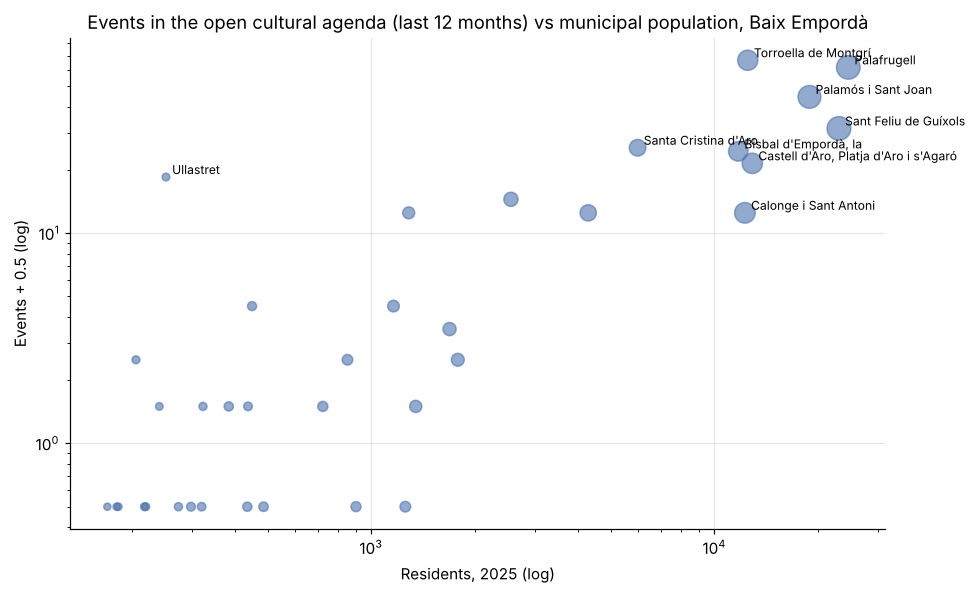

In [7]:
mun["events_last_12m"] = recent.groupby("mun_code")["codi"].nunique().reindex(mun.index, fill_value=0)
print("Comarca total, last 12 months (distinct events):", recent["codi"].nunique())
mun["events_per_1000_residents"] = 1000 * mun["events_last_12m"] / mun["pop_total"]
print(f"Municipalities with ≥1 event in the last 12 months: {(mun['events_last_12m'] > 0).sum()} of {len(mun)}")
top = mun.sort_values("events_last_12m", ascending=False)
share_top5 = top["events_last_12m"].head(5).sum() / mun["events_last_12m"].sum()
print(f"Top 5 municipalities hold {share_top5:.0%} of the municipal event counts (last 12 months)")
display(top[["mun_name", "pop_total", "pop_60_plus", "events_last_12m", "events_per_1000_residents"]].round(1))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(mun["pop_total"], mun["events_last_12m"] + 0.5, s=np.sqrt(mun["pop_60_plus"]) * 3, alpha=0.6, color="#4C72B0")
for code_, r in mun.iterrows():
    if r["events_last_12m"] >= 15 or r["pop_total"] > 10_000:
        ax.annotate(r["mun_name"], (r["pop_total"], r["events_last_12m"] + 0.5), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(title="Events in the open cultural agenda (last 12 months) vs municipal population, Baix Empordà",
       xlabel="Residents, 2025 (log)", ylabel="Events + 0.5 (log)")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "05_agenda_events_vs_population.png", bbox_inches="tight"); plt.show()

In [8]:
senior_events = events.loc[events["mentions_seniors"], ["codi", "denominaci", "data_inici", "place_slug", "tags_categor_es"]].drop_duplicates("codi").copy()
senior_events["start"] = senior_events["data_inici"].str[:10]
# Manual reading of each matched event (title + description): is it AIMED AT seniors?
AIMED_AT_SENIORS = {"40 anys de l'Associació Palamós Gent Gran"}
senior_events["aimed_at_seniors"] = senior_events["denominaci"].isin(AIMED_AT_SENIORS)
display(senior_events[["start", "denominaci", "place_slug", "aimed_at_seniors"]].sort_values("start"))
print(f"Events mentioning seniors (all years): {len(senior_events)} of {events['codi'].nunique()} "
      f"({100 * len(senior_events) / events['codi'].nunique():.1f} %); aimed at seniors: {int(senior_events['aimed_at_seniors'].sum())}")

,start,denominaci,place_slug,aimed_at_seniors
651,2022-11-26,40 anys de l'Associació Palamós Gent Gran,palamos,True
959,2023-05-21,LXII Aplec de Pedralta,sant-feliu-de-guixols,False
1356,2024-02-03,Carnaval de Palamós,palamos,False
1361,2024-02-03,Carnaval de Santa Cristina d'Aro 2024,santa-cristina-d-aro,False
1785,2025-02-22,Carnaval de Sant Feliu de Guíxols 2025,sant-feliu-de-guixols,False
1794,2025-02-22,Carnaval de Santa Cristina d'Aro 2025,santa-cristina-d-aro,False
2112,2026-02-07,Carnaval de Palamós,palamos,False
2115,2026-02-07,Carnaval de Santa Cristina d'Aro 2026,santa-cristina-d-aro,False


Events mentioning seniors (all years): 8 of 1915 (0.4 %); aimed at seniors: 1


The matches other than the association's anniversary are carnival parades: their descriptions mention a seniors' category or seniors taking part. They are general-public events, not activities aimed at seniors.

### 6.2 Facility registers: are casals de gent gran listed?

In [9]:
senior_name = facilities["nom"].str.contains(r"casal|jubilat|gent gran|avis", case=False, regex=True)
# Senior LEISURE venues only (a broad name match also catches health centres and generic "casals")
SENIOR_VENUE = r"jubilat|casal d['’ ]?avis|casal de (?:la )?gent gran|llar del jubilat"
senior_venue = facilities["nom"].str.contains(SENIOR_VENUE, case=False, regex=True) | \
               facilities["categoria"].fillna("").str.contains("Casals de gent gran")
print("Senior leisure venues in the register:"); display(facilities.loc[senior_venue, ["nom", "poblacio", "categoria"]])
senior_category = facilities["categoria"].fillna("").str.contains("gent gran|persones grans", case=False)
print("Facilities in category 'Casals de gent gran' in Baix Empordà:",
      int(facilities["categoria"].fillna("").str.contains("Casals de gent gran").sum()))
print("Catalonia-wide, facilities in that category:", casals_by_comarca["n"].sum(), "in", len(casals_by_comarca), "of 43 comarques")
display(casals_by_comarca)
display(facilities.loc[senior_name | senior_category].groupby("categoria").size().sort_values(ascending=False).to_frame("facilities"))
display(facilities.loc[senior_name & ~senior_category, ["nom", "poblacio", "categoria"]])

relevant_l1 = facilities.groupby(["category_l1", "category_l2"]).size().sort_values(ascending=False)
print("Facilities that could host activities (culture, sport, civic):")
display(relevant_l1.loc[["Cultura", "Esports. Lleure"]].groupby(level=1).sum().sort_values(ascending=False).head(10).to_frame("facilities"))

Senior leisure venues in the register:


,nom,poblacio,categoria
454,LLAR DEL JUBILAT EL RECER DE TORROELLA DE MONTGRÍ,Torroella de Montgrí,Cultura|Altres espais aptes per a l'ús cultural||
520,Casal de Jubilats,Verges,Cultura|Altres espais aptes per a l'ús cultural||


Facilities in category 'Casals de gent gran' in Baix Empordà: 0
Catalonia-wide, facilities in that category: 16 in 7 of 43 comarques


,comarca,n
0,Barcelonès,7
1,Vallès Occidental,3
2,Baix Camp,2
3,Baix Llobregat,1
4,Bages,1
5,Maresme,1
6,Tarragonès,1


,facilities
categoria,
Serveis socials especialitzats|Serveis adreçats a persones grans amb dependència o risc social|Servei de residència assistida per a gent gran de caràcter temporal o permanent|,14
Serveis socials especialitzats|Serveis adreçats a persones grans amb dependència o risc social|Servei de centre de dia per a gent gran de caràcter temporal o permanent|,9
Cultura|Altres espais aptes per a l'ús cultural||,2
Serveis socials especialitzats|Serveis adreçats a persones grans amb dependència o risc social|Servei de llar residència per a gent gran de caràcter temporal o permanent|,2
Salut|Centres sanitaris|4. Centres sociosanitaris|,1
Cultura|Espais escènics i musicals||,1
"Cultura|Centres culturals: ateneus, centres cívics i cases de cultura||",1
Tecnologia. Innovació|Punt TIC||,1


,nom,poblacio,categoria
333,Hospital de dia sociosanitari Palamós Gent Gran. Serveis de Salut ...,PALAMÓS,NaN
342,Consultori local Martí Casals i Echegaray,SANTA CRISTINA D'ARO,NaN
393,CASAL POLIVALENT D'ESCLANYÀ,Begur,"Cultura|Centres culturals: ateneus, centres cívics i cases de cult..."
399,SALA POLIVALENT DEL CASAL POLIVALENT ESCLANYÀ,Begur,Cultura|Espais escènics i musicals||
454,LLAR DEL JUBILAT EL RECER DE TORROELLA DE MONTGRÍ,Torroella de Montgrí,Cultura|Altres espais aptes per a l'ús cultural||
520,Casal de Jubilats,Verges,Cultura|Altres espais aptes per a l'ús cultural||
708,Palamós Gent Gran. Serveis de Salut Integrats Baix Empordà AIE,PALAMÓS,Salut|Centres sanitaris|4. Centres sociosanitaris|
728,Casal de la Vila,"Cruïlles, Monells i Sant Sadurní de l'Heura",Tecnologia. Innovació|Punt TIC||


Facilities that could host activities (culture, sport, civic):


,facilities
category_l2,
Instal·lacions esportives,160
Altres espais aptes per a l'ús cultural,31
"Centres culturals: ateneus, centres cívics i cases de cultura",29
"Museus, col·leccions i centres d'interpretació",25
Espais d'arts visuals,22
Espais escènics i musicals,20
Biblioteques,18
Arxius,12
Cinemes,6


In [10]:
senior_services = social.loc[social["tipologia"].str.contains("gent gran|persones grans", case=False)]
print(f"Social services registered in Baix Empordà: {len(social)}; aimed at older people: {len(senior_services)}")
display(senior_services.groupby("tipologia").size().sort_values(ascending=False).to_frame("services"))

Social services registered in Baix Empordà: 83; aimed at older people: 25


,services
tipologia,
Servei de residència assistida per a gent gran de caràcter temporal o permanent,14
Servei de centre de dia per a gent gran de caràcter temporal o permanent,9
Servei de llar residència per a gent gran de caràcter temporal o permanent,2


### 6.3 Municipal websites

In [11]:
summary_web = pd.Series({
    "municipalities": len(web),
    "website reachable (automated check)": int(web["reachable"].sum()),
    "homepage links to an agenda": int(web["has_agenda_link"].sum()),
    "homepage links to a seniors / casal page": int(web["has_senior_link"].sum()),
    "agenda page mentions seniors": int(web["agenda_mentions_seniors"].sum()),
})
display(summary_web.to_frame("count"))
display(web.loc[web["has_senior_link"], ["municipi", "senior_links"]])
display(web.loc[web["agenda_mentions_seniors"], ["municipi", "agenda_checked_url", "senior_terms_on_agenda"]])

,count
municipalities,36
website reachable (automated check),29
homepage links to an agenda,25
homepage links to a seniors / casal page,5
agenda page mentions seniors,3


,municipi,senior_links
mun_code,,
170139,Begur,[https://begur.cat/serveis/gent-gran/]
170486,"Castell d'Aro, Platja d'Aro i s'Agaró","[https://ciutada.platjadaro.com/el-nadal-de-la-gent-gran-3/, https..."
171181,Palamós i Sant Joan,[https://www.palamos.cat:443/palamos/ajuntament/punts.aspx?punt=p52]
171241,Pals,[https://www.pals.cat/ca/arees/accio-social-salut-gent-gran-i-igua...
171997,Torroella de Montgrí,[https://www.torroella-estartit.cat/ca/serveis-socials-gent-gran-c...


,municipi,agenda_checked_url,senior_terms_on_agenda
mun_code,,,
170139,Begur,https://begur.cat/agenda/,1.0
170486,"Castell d'Aro, Platja d'Aro i s'Agaró",https://agenda.platjadaro.com/,1.0
171241,Pals,https://www.pals.cat/ca/agenda/,2.0


### 6.4 Visibility by municipality

,municipalities,residents_60_plus,in_open_agenda_12m,has_agenda_link,has_senior_link,agenda_mentions_seniors,senior_place_in_register,website_not_checked
size_class,,,,,,,,
"< 1,000 residents",20,2308.0,9,15,0,0,0,1
"1,000–4,999",8,4928.0,7,5,2,2,1,3
"≥ 5,000",8,33227.0,8,5,3,1,1,3


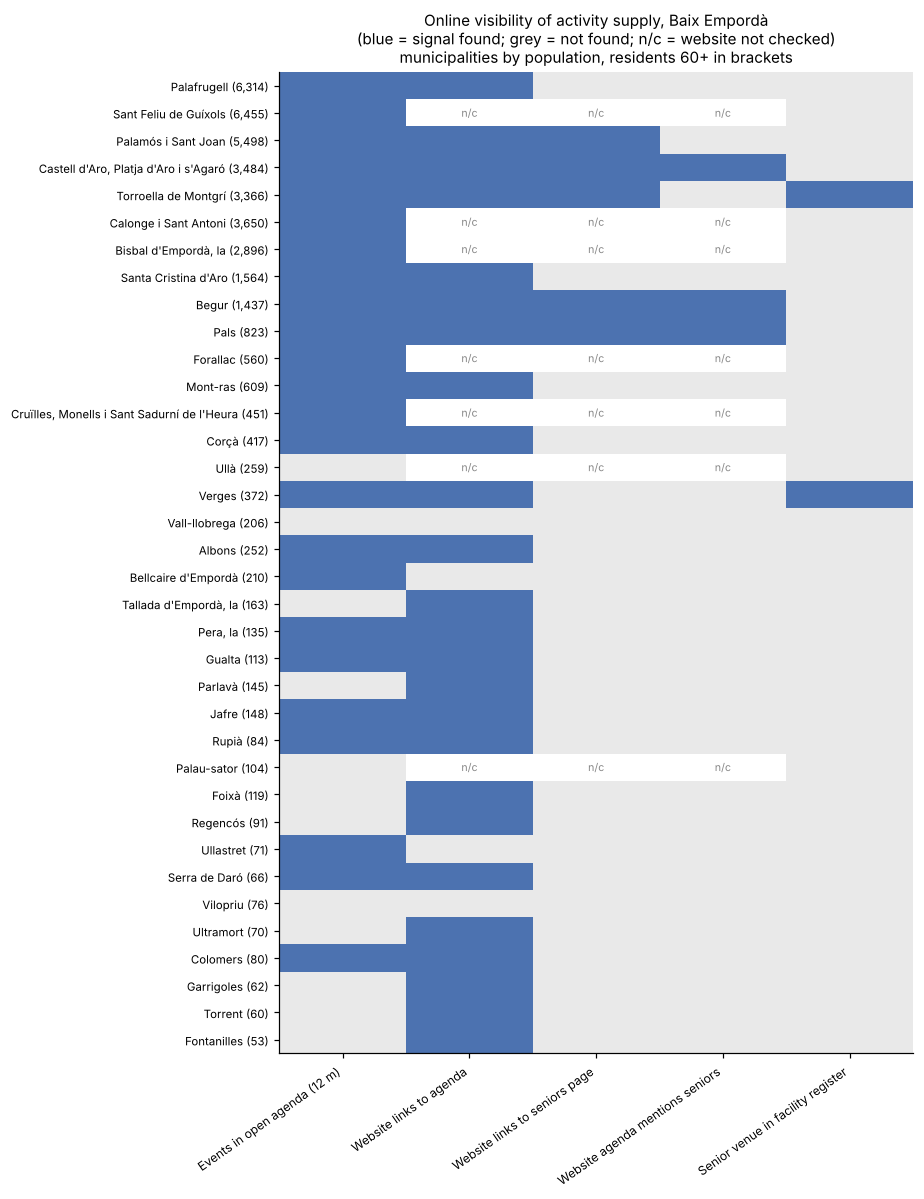

In [12]:
mun = mun.join(web[["reachable", "has_agenda_link", "has_senior_link", "agenda_mentions_seniors"]])
registered_senior_place = facilities.loc[senior_venue].groupby("mun_code").size()
mun["senior_place_in_register"] = registered_senior_place.reindex(mun.index, fill_value=0) > 0
mun["in_open_agenda_12m"] = mun["events_last_12m"] > 0

signals = ["in_open_agenda_12m", "has_agenda_link", "has_senior_link", "agenda_mentions_seniors", "senior_place_in_register"]
labels = ["Events in open agenda (12 m)", "Website links to agenda", "Website links to seniors page",
          "Website agenda mentions seniors", "Senior venue in facility register"]
by_size = mun.groupby("size_class", observed=True).agg(
    municipalities=("mun_name", "size"), residents_60_plus=("pop_60_plus", "sum"),
    **{s: (s, "sum") for s in signals}, website_not_checked=("reachable", lambda s: int((~s).sum())))
display(by_size)

order = mun.sort_values("pop_total", ascending=False)
matrix = order[signals].astype(float).copy()
matrix.loc[~order["reachable"], ["has_agenda_link", "has_senior_link", "agenda_mentions_seniors"]] = np.nan
fig, ax = plt.subplots(figsize=(8.5, 11))
cmap = plt.matplotlib.colors.ListedColormap(["#E9E9E9", "#4C72B0"]); cmap.set_bad("#FFFFFF")
ax.imshow(np.ma.masked_invalid(matrix.values), cmap=cmap, aspect="auto", vmin=0, vmax=1)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        if np.isnan(matrix.values[i, j]):
            ax.text(j, i, "n/c", ha="center", va="center", fontsize=7, color="#888888")
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(order)), [f"{n} ({int(p):,})" for n, p in zip(order["mun_name"], order["pop_60_plus"])], fontsize=7.5)
ax.grid(False)
ax.set_title("Online visibility of activity supply, Baix Empordà\n(blue = signal found; grey = not found; n/c = website not checked)\nmunicipalities by population, residents 60+ in brackets", fontsize=10)
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "05_visibility_matrix.png", bbox_inches="tight"); plt.show()

In [13]:
seniors_covered = {s: 100 * mun.loc[mun[s], "pop_60_plus"].sum() / mun["pop_60_plus"].sum() for s in signals}
display(pd.Series(seniors_covered, name="% of comarca's residents 60+ living in municipalities with the signal").round(1).to_frame())

mun_out = mun.reset_index()[["mun_code", "mun_name", "pop_total", "pop_60_plus", "share_60_plus", "size_class", "web",
                             "events_last_12m", "events_per_1000_residents"] + signals + ["reachable"]]
mun_out.to_csv(DATA_PROCESSED / "supply_visibility_baix_emporda.csv", index=False, encoding="utf-8-sig")
senior_events.to_csv(DATA_PROCESSED / "agenda_events_mentioning_seniors_baix_emporda.csv", index=False, encoding="utf-8-sig")
print("Exported supply_visibility_baix_emporda.csv and agenda_events_mentioning_seniors_baix_emporda.csv")

,% of comarca's residents 60+ living in municipalities with the signal
in_open_agenda_12m,96.5
has_agenda_link,63.1
has_senior_link,36.1
agenda_mentions_seniors,14.2
senior_place_in_register,9.2


Exported supply_visibility_baix_emporda.csv and agenda_events_mentioning_seniors_baix_emporda.csv


## 7. Interpretation

Facts (measured above), observations and hypotheses are kept apart.

**Facts.**

- *Open cultural agenda.* 1,915 distinct events have been published since 2018, nearly all from 2021 onwards. The last 12 months had **351 events**, and 30 are announced from the retrieval date. Of the 36 municipalities, 24 had at least one event, and they are home to 96.5 % of the comarca's residents aged 60+. Five towns account for 63 % of the municipal counts: Torroella de Montgrí, Palafrugell, Palamós, Sant Feliu de Guíxols and Santa Cristina d'Aro. The most common categories are children's events, theatre, concerts, festivals and guided visits; 32 % are free.
- *Senior content in the agenda.* Only **8 of 1,915 events (0.4 %) mention seniors at all**, and only **one** is aimed at them: the 40th anniversary of the Associació Palamós Gent Gran (2022). None of the 351 events in the last 12 months is aimed at seniors.
- *Registers.* No facility in Baix Empordà is in the "Casals de gent gran" category. In the whole of Catalonia that category holds only 16 facilities, spread over 7 of the 43 comarques. Two senior leisure venues appear under generic cultural categories: the Llar del Jubilat El Recer in Torroella de Montgrí and the Casal de Jubilats in Verges. The social-services register lists 25 services for older people in the comarca: 14 residences, 9 day centres and 2 residential homes. All of them are **care** services, not leisure.
- *Municipal websites.* 29 of the 36 sites could be checked automatically. 25 link to an agenda from the homepage, 5 link to a page for seniors or a casal (Begur, Castell-Platja d'Aro, Palamós, Pals, Torroella de Montgrí), and 3 agenda pages mention seniors. None of the 20 municipalities with fewer than 1,000 residents links to a seniors page.

**Observations.**

- *General cultural supply is quite visible online; senior-specific supply is almost invisible.* Seniors are well covered by municipalities that publish *some* agenda (96.5 % of seniors live in one with open-agenda events in the last year). But the share living where a *senior-specific* signal appears is much lower: 36 % (website senior page), 14 % (agenda mentioning seniors) and 9 % (registered senior venue).
- *What does exist is scattered.* Casals and senior programmes clearly exist: a seniors' association in Palamós, the Llar del Jubilat in Torroella and the Casal de Jubilats in Verges are registered, and Begur, Pals and others have senior pages. But they surface in different places (municipal pages, registers under generic categories), not in the shared open agenda. Official registers treat seniors almost only as recipients of care.

**Hypotheses (to test in the inventory and the survey).**

- **H7:** Activities for seniors exist but are *fragmented and hard to find online*: spread across municipal pages and offline channels, and not aggregated. If confirmed, this would support an information-aggregation value proposition. It would **not** show that seniors want a digital channel (see H4: 65–74 use the internet, but few transact online).
- **H8:** Casals and senior associations publicise mainly offline (noticeboards, meetings, WhatsApp, word of mouth). Their supply can only be inventoried by contacting them directly.
- **H9:** In small municipalities (< 1,000 residents) the senior offer may be organised at comarca level, or shared between towns (Consell Comarcal, neighbouring casals), rather than per municipality.

## 8. Limitations

- **Visibility, not existence.** Every result measures what can be found online with these sources and methods. It does not measure what exists. Casals, associations and municipal programmes often publicise activities through noticeboards, WhatsApp groups, parish sheets, local radio or word of mouth.
- **The open agenda is voluntary.** Organisers choose whether to publish there, so its coverage varies by municipality and grew strongly after 2021.
- **The keyword search is narrow and in Catalan.** Senior activities described without these words (e.g. "gimnàstica de manteniment", "tai-txi", "cursos per a adults") are missed. The single "aimed at seniors" classification was made by reading the matches; it was not systematic.
- **The website check is shallow.** It reads one homepage and one agenda page. Links loaded by JavaScript, PDFs and social media are not seen. Seven sites could not be checked (blocked or not responding): those cells are "not checked", not "absent".
- **One comarca, one day.** The results are a snapshot of Baix Empordà on 26 Nov 2026 and may not transfer to the P1 and P4 comarques.

## 9. Conclusions and next steps

**Conclusions**

1. Online, the cultural agenda of Baix Empordà is rich (351 events in a year, in 24 of 36 municipalities), but **almost none of it is aimed at seniors**: one event in eight years.
2. Official registers do not list casals de gent gran in the comarca (and barely in Catalonia). They show seniors mainly through care services.
3. Municipal websites are the best online source: 5 of 29 checked sites have a seniors or casal page. Even so, senior-specific information reaches municipalities that are home to only about a third of the comarca's seniors.
4. Lack of online information is **not** evidence of lack of activities. The registered casals show the offer exists. A supply inventory based only on online sources would badly undercount it.

**Next steps (recommended)**

- [ ] Design the **inventory schema** (organiser, type, activity, category, target audience if stated, price, frequency, place, channel where it is publicised, source, date collected).
- [ ] **Pilot in Baix Empordà:** read the 5 municipal senior pages and the 3 agenda pages manually; contact the casals and associations of Torroella de Montgrí, Verges, Palamós and Begur, plus the Consell Comarcal's social services, to collect their offline programmes.
- [ ] Record for each activity **how it is publicised** (online, offline, both). This tests H7–H8 directly.
- [ ] Repeat the online-visibility check for the P1 and P4 candidate comarques (Vallès Occidental, Berguedà) with the same scripts, to compare profiles.
- [ ] In the survey, ask seniors **how they currently find out** about activities, and whether they would use an aggregated listing.